# Step 3: Machine Learning Models - Car Price Prediction

We predict the **price** of a car using **3 algorithms**:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

For every model we calculate **R² score, MAE, RMSE and Accuracy**.

**What do these mean?**
- **R² score** - how much of the price changes the model can explain (closer to 1 is better)
- **MAE** - average mistake in price (smaller is better)
- **RMSE** - like MAE but punishes big mistakes more (smaller is better)
- **Accuracy** - `100 - MAPE`. MAPE is the average % mistake, so accuracy tells us how close the predictions are to the real prices *in percent*. (Normal "accuracy" is for classification, so for price prediction we use this version.)

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (r2_score, mean_absolute_error,
                             mean_squared_error, mean_absolute_percentage_error)

## 2. Load the clean data

In [2]:
df = pd.read_csv("cars_cleaned.csv")
print(df.shape)
df.head()

(57883, 16)


,Manufacturer,Model,Prod_Year,Category,Leather_Interior,Fuel_Type,Engine_Volume,Mileage,Cylinders,Gear_box_type,Drive_Wheels,Doors,Color,Airbags,Price,Turbo
0,Audi,Q7,2008,SUV,No,Electric,4.4,86140.0,6,Automatic,Front-wheel,5,Grey,1,30396.057968,0
1,Mercedes-Benz,C-Class,2021,Hatchback,No,Petrol,3.6,180266.0,4,Tiptronic,Front-wheel,5,Grey,2,41415.845710,0
2,Kia,Sportage,2008,Coupe,Yes,Electric,1.3,247950.0,6,Automatic,4x4,4,Grey,6,10042.988409,0
3,Ford,Explorer,2008,Minivan,No,Diesel,2.0,172359.0,4,Automatic,4x4,4,Blue,5,7180.349761,0
4,Audi,A6,2015,Hatchback,No,Diesel,3.5,48767.0,4,CVT,Front-wheel,5,Black,5,29688.279552,0


## 3. Choose the columns to use
We drop `Model` because the `Manufacturer` column already carries the brand information, and it keeps our data small and simple.

In [3]:
df = df.drop(columns=["Model"])
df.columns.tolist()

['Manufacturer',
 'Prod_Year',
 'Category',
 'Leather_Interior',
 'Fuel_Type',
 'Engine_Volume',
 'Mileage',
 'Cylinders',
 'Gear_box_type',
 'Drive_Wheels',
 'Doors',
 'Color',
 'Airbags',
 'Price',
 'Turbo']

## 4. Split into inputs (X) and target (y)
- `X` = the car details we give to the model
- `y` = the `Price` we want to predict

In [4]:
X = df.drop(columns=["Price"])
y = df["Price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (57883, 14)
y shape: (57883,)


## 5. Convert text columns into numbers
Models only understand numbers, so we use **one-hot encoding** (`get_dummies`). For example, `Fuel_Type` becomes separate 0/1 columns.

In [5]:
X = pd.get_dummies(X, drop_first=True)
X = X.astype(float)

print("X shape after encoding:", X.shape)
X.head()

X shape after encoding: (57883, 36)


,Prod_Year,Engine_Volume,Mileage,Cylinders,Doors,Airbags,Turbo,Manufacturer_BMW,Manufacturer_Chevrolet,Manufacturer_Ford,...,Gear_box_type_Manual,Gear_box_type_Tiptronic,Drive_Wheels_Front-wheel,Drive_Wheels_Rear-wheel,Color_Blue,Color_Brown,Color_Grey,Color_Red,Color_Silver,Color_White
0,2008.0,4.4,86140.0,6.0,5.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,2021.0,3.6,180266.0,4.0,5.0,2.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,2008.0,1.3,247950.0,6.0,4.0,6.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,2008.0,2.0,172359.0,4.0,4.0,5.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,2015.0,3.5,48767.0,4.0,5.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 6. Split into training and testing data
We train on 80% of the cars and test on the other 20% that the model has never seen.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 46306
Testing rows : 11577


## 7. A helper function to measure each model
We write it once and reuse it for all 3 models.

In [7]:
def evaluate_model(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    accuracy = 100 - mean_absolute_percentage_error(y_true, y_pred) * 100

    print(f"{name}")
    print(f"  R2 score : {r2:.4f}")
    print(f"  MAE      : {mae:.2f}")
    print(f"  RMSE     : {rmse:.2f}")
    print(f"  Accuracy : {accuracy:.2f} %")

    return {"Model": name, "R2": r2, "MAE": mae, "RMSE": rmse, "Accuracy (%)": accuracy}

In [8]:
results = []   # we will store the scores of all models here
models = {}    # and the trained models here

## 8. Model 1: Linear Regression
The simplest model. It draws the best straight-line relationship between the inputs and the price.

In [9]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)          # learn from training data

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](36,)","[ 795.38,3970.49, -0.05,..., -23.69, -14.75, 20.81]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](36,)","['Prod_Year','Engine_Volume','Mileage',...,'Color_Red','Color_Silver', 'Color_White']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.586e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,36
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(36)


In [10]:
lr_pred = lr_model.predict(X_test)      # predict prices of unseen cars
results.append(evaluate_model("Linear Regression", y_test, lr_pred))
models["Linear Regression"] = lr_model

Linear Regression
  R2 score : 0.9046
  MAE      : 2693.78
  RMSE     : 3517.75
  Accuracy : 84.69 %


## 9. Model 2: Decision Tree
The model asks a series of yes/no questions (like 'is the year > 2015?') to reach a price.

We limit the tree (`max_depth=12`, `min_samples_leaf=20`) so it does not simply memorize the training data (called *overfitting*).

In [11]:
dt_model = DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42)
dt_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [12]:
dt_pred = dt_model.predict(X_test)
results.append(evaluate_model("Decision Tree", y_test, dt_pred))
models["Decision Tree"] = dt_model

Decision Tree
  R2 score : 0.8814
  MAE      : 3027.87
  RMSE     : 3922.83
  Accuracy : 83.30 %


## 10. Model 3: Random Forest
Many decision trees working together; their answers are averaged. This is usually more stable than one tree.

In [13]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10,
                                 random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [14]:
rf_pred = rf_model.predict(X_test)
results.append(evaluate_model("Random Forest", y_test, rf_pred))
models["Random Forest"] = rf_model

Random Forest
  R2 score : 0.8927
  MAE      : 2881.60
  RMSE     : 3731.71
  Accuracy : 83.32 %


## 11. Compare all 3 models

In [15]:
results_df = pd.DataFrame(results)
results_df = results_df.round(4)
results_df

,Model,R2,MAE,RMSE,Accuracy (%)
0,Linear Regression,0.9046,2693.7781,3517.7534,84.6927
1,Decision Tree,0.8814,3027.8678,3922.8298,83.3033
2,Random Forest,0.8927,2881.5964,3731.7113,83.3176


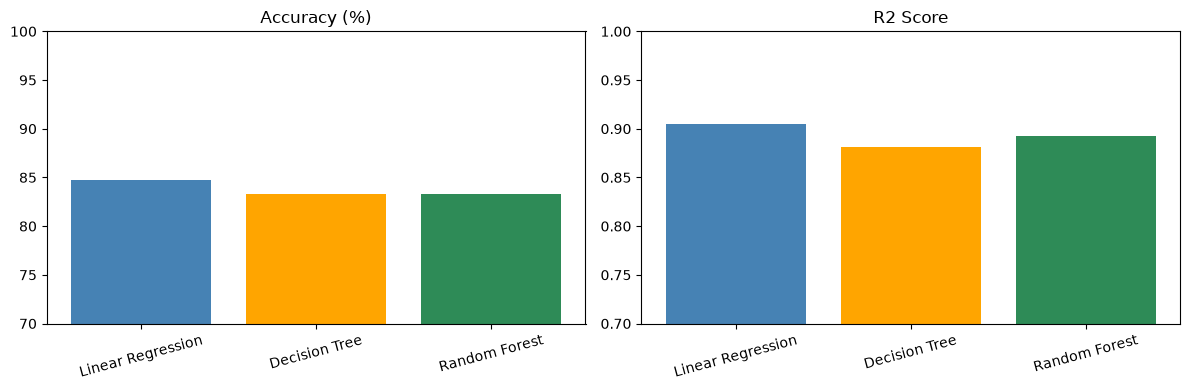

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(results_df["Model"], results_df["Accuracy (%)"], color=["steelblue", "orange", "seagreen"])
axes[0].set_title("Accuracy (%)")
axes[0].set_ylim(70, 100)
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(results_df["Model"], results_df["R2"], color=["steelblue", "orange", "seagreen"])
axes[1].set_title("R2 Score")
axes[1].set_ylim(0.7, 1.0)
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## 12. Check for overfitting
If the training score is much higher than the test score, the model is memorizing instead of learning. Here the two scores are close, which is good.

In [17]:
for name, model in models.items():
    train_r2 = model.score(X_train, y_train)
    test_r2 = model.score(X_test, y_test)
    print(f"{name:18s} Train R2 = {train_r2:.4f} | Test R2 = {test_r2:.4f}")

Linear Regression  Train R2 = 0.9013 | Test R2 = 0.9046
Decision Tree      Train R2 = 0.9012 | Test R2 = 0.8814
Random Forest      Train R2 = 0.9086 | Test R2 = 0.8927


## 13. Which features matter most? (Random Forest)

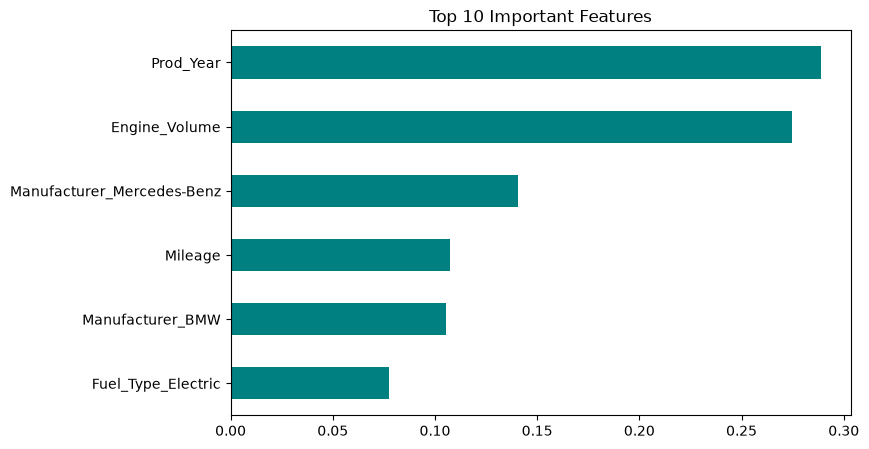

In [22]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns)
top10 = importance.sort_values(ascending=False).head(6)

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 Important Features")
plt.show()

## 14. Check the accuracy range
Our goal was an accuracy between **80% and 90%**.

In [19]:
for _, row in results_df.iterrows():
    ok = 80 <= row["Accuracy (%)"] <= 90
    print(f"{row['Model']:18s} {row['Accuracy (%)']:.2f} %  ->  {'within 80-90%' if ok else 'outside range'}")

Linear Regression  84.69 %  ->  within 80-90%
Decision Tree      83.30 %  ->  within 80-90%
Random Forest      83.32 %  ->  within 80-90%


## 15. Compare a few real vs predicted prices

In [20]:
best_name = results_df.sort_values("RMSE").iloc[0]["Model"]
best_model = models[best_name]
print("Best model (lowest RMSE):", best_name)

comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": best_model.predict(X_test)[:10]
}).round(0)
comparison

Best model (lowest RMSE): Linear Regression


,Actual Price,Predicted Price
0,32871.0,27114.0
1,14152.0,11893.0
2,26848.0,21395.0
3,5873.0,9071.0
4,19106.0,22546.0
5,13673.0,12708.0
6,29159.0,32750.0
7,39684.0,35628.0
8,20749.0,19436.0
9,15383.0,21421.0


## 16. Save the best model
`CAR.py` will load these two files to predict prices.

In [21]:
joblib.dump(best_model, "car_price_model.pkl")
joblib.dump(list(X.columns), "model_columns.pkl")
print("Saved: car_price_model.pkl and model_columns.pkl")

Saved: car_price_model.pkl and model_columns.pkl


**Done!** Run the app from your terminal with:

```
streamlit run CAR.py
```